In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Customer Segmentation using RFM Analysis and K-Means
Dataset: Online Retail II (UCI Machine Learning Repository) | Analyst: Saima Hashmi
Objective: Segment customers by purchasing behaviour (Recency, Frequency, Monetary) using K-Means clustering and suggest a marketing action for each segment.

In [10]:
   !ls -lh

total 44M
-rw-r--r-- 1 root root  44M Oct 28 07:21 online_retail_II.xlsx
drwxr-xr-x 1 root root 4.0K Oct 26 22:18 sample_data


In [11]:
   sheets = pd.read_excel("online_retail_II.xlsx",
                          sheet_name=["Year 2009-2010", "Year 2010-2011"])
   df1 = sheets["Year 2009-2010"]
   df2 = sheets["Year 2010-2011"]
   print("Sheet 1:", df1.shape, "| Sheet 2:", df2.shape)

   df = pd.concat([df1, df2], ignore_index=True)
   print("Combined:", df.shape)

Sheet 1: (525461, 8) | Sheet 2: (541910, 8)
Combined: (1067371, 8)


In [12]:
df.to_csv("online_retail_II.csv", index=False)

In [13]:
df.info()
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
Duplicate rows: 34335
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [14]:
print("Missing Customer ID: {:.1f}%".format(df['Customer ID'].isnull().mean() * 100))
print("Cancelled invoices (start with C):", df['Invoice'].astype(str).str.startswith('C').sum())
print("Negative/zero Quantity:", (df['Quantity'] <= 0).sum())
print("Negative/zero Price:", (df['Price'] <= 0).sum())
print("Unique customers:", df['Customer ID'].nunique())
print("Unique invoices:", df['Invoice'].nunique())
print("Countries:", df['Country'].nunique())

Missing Customer ID: 22.8%
Cancelled invoices (start with C): 19494
Negative/zero Quantity: 22950
Negative/zero Price: 6207
Unique customers: 5942
Unique invoices: 53628
Countries: 43


## Initial Data Inspection

**Observations:**
- The combined dataset has **1,067,371 rows and 8 columns**, covering **1 Dec 2009 to 9 Dec 2011**.
- **Customer ID is missing in 243,007 rows (22.8%)**. Since segmentation is done per customer, these rows cannot be used.
- **Description is missing in 4,382 rows**, and there are **34,335 exact duplicate rows** (some may come from overlap between the two yearly sheets).
- There are **19,494 rows from cancelled invoices** (invoice number starts with "C"), **22,950 rows with zero or negative Quantity** and **6,207 rows with zero or negative Price**. These are returns, cancellations or data-entry adjustments and do not represent real purchases.
- There are **5,942 unique customers**, **53,628 unique invoices** and **43 countries**.
- Customer ID is stored as a float (e.g. 13085.0), so it will be converted to a string ID after cleaning.

In [15]:
codes = df['StockCode'].astype(str)
print(sorted(codes[~codes.str.match(r'^\d{5}')].unique())[:40])

['ADJUST', 'ADJUST2', 'AMAZONFEE', 'B', 'BANK CHARGES', 'C2', 'C3', 'CRUK', 'D', 'DCGS0003', 'DCGS0004', 'DCGS0006', 'DCGS0016', 'DCGS0027', 'DCGS0036', 'DCGS0037', 'DCGS0039', 'DCGS0041', 'DCGS0044', 'DCGS0053', 'DCGS0055', 'DCGS0056', 'DCGS0057', 'DCGS0058', 'DCGS0059', 'DCGS0060', 'DCGS0062', 'DCGS0066N', 'DCGS0066P', 'DCGS0067', 'DCGS0068', 'DCGS0069', 'DCGS0070', 'DCGS0071', 'DCGS0072', 'DCGS0073', 'DCGS0074', 'DCGS0075', 'DCGS0076', 'DCGSLBOY']


In [16]:
original_rows = len(df)
clean = df.copy()
log = []

def step(name, new_df):
    global clean
    log.append((name, len(clean) - len(new_df), len(new_df)))
    clean = new_df

step("Remove duplicate rows", clean.drop_duplicates())
step("Remove missing Customer ID", clean.dropna(subset=['Customer ID']))
step("Remove cancelled invoices (start with C)",
     clean[~clean['Invoice'].astype(str).str.startswith('C')])
step("Remove Quantity <= 0", clean[clean['Quantity'] > 0])
step("Remove Price <= 0", clean[clean['Price'] > 0])
step("Remove non-product StockCodes",
     clean[clean['StockCode'].astype(str).str.match(r'^\d{5}')])

clean['Customer ID'] = clean['Customer ID'].astype(int).astype(str)
clean['TotalPrice'] = clean['Quantity'] * clean['Price']

print("Original rows:", original_rows)
print("Final rows:", len(clean), "| Unique customers:", clean['Customer ID'].nunique())
pd.DataFrame(log, columns=['Step', 'Rows removed', 'Rows remaining'])

Original rows: 1067371
Final rows: 776577 | Unique customers: 5852


,Step,Rows removed,Rows remaining
0,Remove duplicate rows,34335,1033036
1,Remove missing Customer ID,235151,797885
2,Remove cancelled invoices (start with C),18390,779495
3,Remove Quantity <= 0,0,779495
4,Remove Price <= 0,70,779425
5,Remove non-product StockCodes,2848,776577


## Data Cleaning

**Decisions and rows removed (in order):**
1. **Duplicate rows: 34,335 removed.** Exact copies of other rows, partly caused by overlap between the two yearly sheets.
2. **Missing Customer ID: 235,151 removed.** Segmentation is done per customer, so rows without an ID cannot be assigned to anyone.
3. **Cancelled invoices (start with "C"): 18,390 removed.** These are returns/cancellations, not purchases.
4. **Quantity <= 0: 0 removed.** All negative quantities had already been removed in the earlier steps (they belonged to cancelled invoices or missing IDs).
5. **Price <= 0: 70 removed.** Zero-priced rows are free items or adjustments and would distort spending.
6. **Non-product StockCodes: 2,848 removed.** Codes that do not start with a 5-digit product number (such as postage, bank charges or manual adjustments) are not products customers chose to buy.

**Result:** the dataset went from **1,067,371 to 776,577 rows** (about 27% removed) and from 5,942 to **5,852 customers**. Customer ID was converted from float to a string ID, and a new column `TotalPrice = Quantity × Price` was created.

Note: missing Customer IDs were removed instead of imputed, because an ID cannot be guessed and wrongly assigned rows would corrupt the RFM values.

## Descriptive Statistics

                      Before   After
Rows                 1067371  776577
Missing Customer ID   243007       0
Duplicate rows         34335       0
Unique customers        5942    5852 

Average purchase value (per invoice): mean = 466.43, median = 302.55
Purchase frequency (invoices per customer): mean = 6.25, median = 3
Historical customer value (total spend per customer): mean = 2916.71, median = 856.02


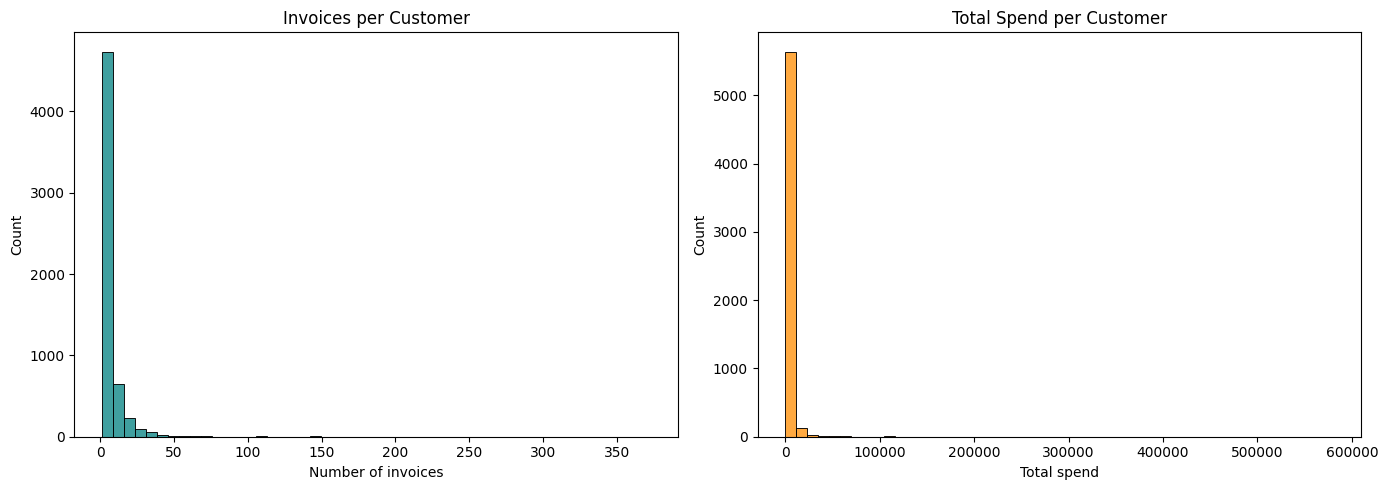

In [17]:
# Before vs after summary
summary = pd.DataFrame({
    'Before': [len(df), df['Customer ID'].isnull().sum(), df.duplicated().sum(), df['Customer ID'].nunique()],
    'After':  [len(clean), clean['Customer ID'].isnull().sum(), clean.duplicated().sum(), clean['Customer ID'].nunique()]
}, index=['Rows', 'Missing Customer ID', 'Duplicate rows', 'Unique customers'])
print(summary, "\n")

# Per-invoice and per-customer figures
invoice_totals = clean.groupby(['Customer ID', 'Invoice'])['TotalPrice'].sum().reset_index()
orders_per_customer = invoice_totals.groupby('Customer ID')['Invoice'].nunique()
spend_per_customer = clean.groupby('Customer ID')['TotalPrice'].sum()

print("Average purchase value (per invoice): mean = {:.2f}, median = {:.2f}".format(
    invoice_totals['TotalPrice'].mean(), invoice_totals['TotalPrice'].median()))
print("Purchase frequency (invoices per customer): mean = {:.2f}, median = {:.0f}".format(
    orders_per_customer.mean(), orders_per_customer.median()))
print("Historical customer value (total spend per customer): mean = {:.2f}, median = {:.2f}".format(
    spend_per_customer.mean(), spend_per_customer.median()))

# Distribution charts
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(orders_per_customer, bins=50, color='teal', ax=ax[0])
ax[0].set_title('Invoices per Customer')
ax[0].set_xlabel('Number of invoices')
sns.histplot(spend_per_customer, bins=50, color='darkorange', ax=ax[1])
ax[1].set_title('Total Spend per Customer')
ax[1].set_xlabel('Total spend')
plt.tight_layout()
plt.show()

### Observations: Descriptive Statistics

- **Before vs after cleaning:** rows dropped from 1,067,371 to 776,577, customers from 5,942 to 5,852, and missing Customer IDs and duplicate rows are now 0.
- **Average purchase value (per invoice):** mean 466.43 and median 302.55. The mean is well above the median, so a few very large invoices pull the average up.
- **Purchase frequency:** customers place on average 6.25 invoices, but the median is only 3. Half of the customers bought three times or fewer, while a small group of very active customers (up to about 350 invoices) raises the mean.
- **Historical customer value (total spend over two years):** mean 2,916.71 versus median 856.02. The mean is roughly 3.4 times the median.
- **Charts:** both histograms are extremely right-skewed. Almost all customers sit in the first bar (few invoices, low spend), while a very small number of customers spend far more than everyone else (the spend axis stretches to about 600,000).
- **Implication:** since these variables are so skewed, K-Means (which uses distances) would be dominated by a handful of big customers, so the RFM features should be transformed (for example with a log transform) and scaled before clustering.
- Note: "customer lifetime value" here means historical value (total spend over the two years in the data), not a predicted future value.

## RFM Feature Engineering

RFM summarises each customer's behaviour with three numbers:
- **Recency:** days since the customer's last purchase (lower is better)
- **Frequency:** number of distinct invoices the customer placed
- **Monetary:** total amount the customer spent

The snapshot date is one day after the last transaction in the dataset.

Snapshot date: 2011-12-10 12:50:00
(5852, 4)
       Recency  Frequency   Monetary
count  5852.00    5852.00    5852.00
mean    200.20       6.25    2916.71
std     208.51      12.75   14306.85
min       1.00       1.00       2.95
25%      25.00       1.00     339.58
50%      95.00       3.00     856.02
75%     379.00       7.00    2241.03
max     739.00     373.00  580987.04

Skewness:
 Recency       0.89
Frequency    12.04
Monetary     25.33
dtype: float64


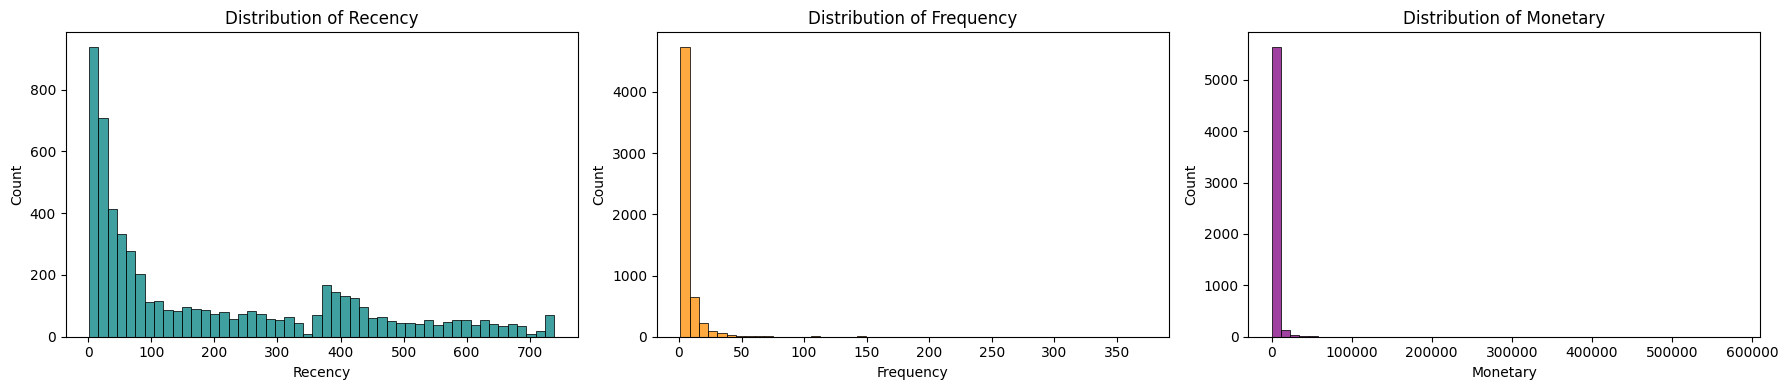

,Customer ID,Recency,Frequency,Monetary
0,12346,326,3,77352.96
1,12347,2,8,4921.53
2,12348,75,5,1658.40
3,12349,19,3,3678.69
4,12350,310,1,294.40


In [18]:
snapshot_date = clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

rfm = clean.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

print(rfm.shape)
print(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))
print("\nSkewness:\n", rfm[['Recency', 'Frequency', 'Monetary']].skew().round(2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, col, color in zip(ax, ['Recency', 'Frequency', 'Monetary'], ['teal', 'darkorange', 'purple']):
    sns.histplot(rfm[col], bins=50, color=color, ax=a)
    a.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

rfm.head()

### Observations: RFM Features

- The RFM table has **5,852 customers**. The snapshot date is **10 Dec 2011**, one day after the last transaction in the data.
- **Recency:** mean 200 days, median 95 days (range 1 to 739). Many customers bought recently, but the histogram has a second smaller bump around 400 days, which suggests a group of customers who bought in the first year and have not returned. Skewness is moderate (0.89).
- **Frequency:** mean 6.25 and median 3 invoices, with a maximum of 373. Skewness is very high (**12.04**), so most customers are occasional buyers and a few are extremely frequent.
- **Monetary:** mean 2,916.71 but median 856.02, with a maximum of 580,987. Skewness is the highest (**25.33**), so a very small number of customers account for a large share of revenue (the company mainly sells to wholesalers, so large buyers are expected).
- Because Frequency and Monetary are so skewed and are on very different scales (Recency in hundreds of days, Monetary in thousands), clustering on the raw values would be dominated by a few big customers. I will therefore apply a **log transform** followed by **StandardScaler** before K-Means.
- Large customers were kept (not removed as outliers), since they are genuine wholesale buyers and are exactly the segment a business would want to identify.

## Feature Selection, Scaling and Choosing K

**Features:** Recency, Frequency and Monetary (RFM), because together they describe how recently, how often and how much a customer buys.

**Preprocessing:** log(1 + x) transform to reduce skewness, then StandardScaler so that all three features have mean 0 and standard deviation 1 and contribute equally to the distance calculation in K-Means.

Skewness before:
 Recency       0.89
Frequency    12.04
Monetary     25.33
dtype: float64

Skewness after log transform:
 Recency     -0.49
Frequency    1.00
Monetary     0.27
dtype: float64


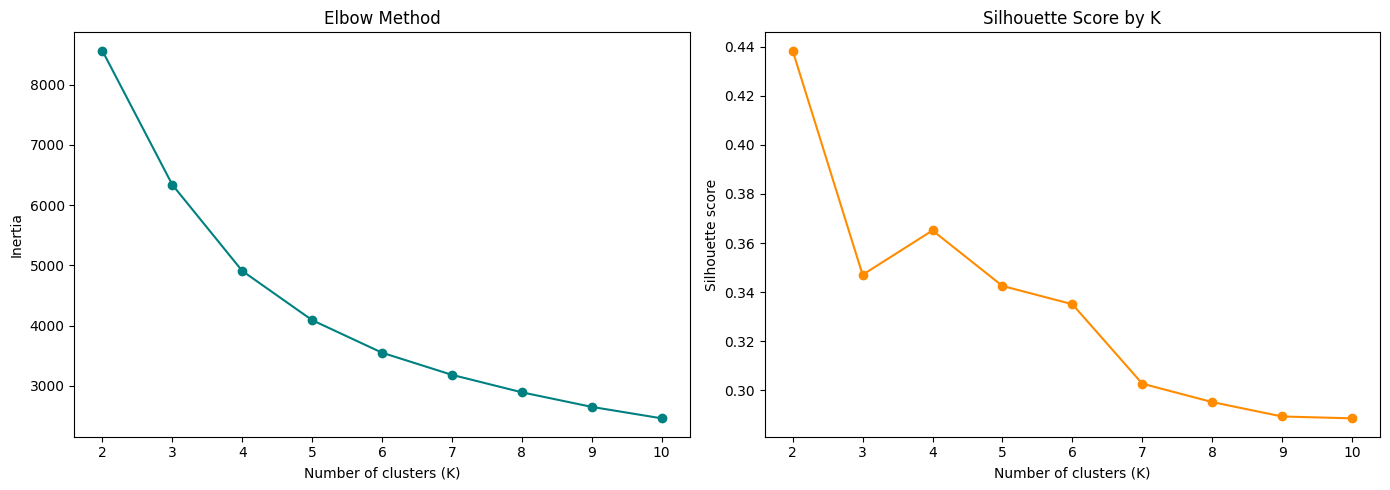

K=2: silhouette = 0.438
K=3: silhouette = 0.347
K=4: silhouette = 0.365
K=5: silhouette = 0.343
K=6: silhouette = 0.335
K=7: silhouette = 0.303
K=8: silhouette = 0.295
K=9: silhouette = 0.289
K=10: silhouette = 0.289


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = ['Recency', 'Frequency', 'Monetary']

# 1) Log transform + 2) scaling
rfm_log = np.log1p(rfm[features])
print("Skewness before:\n", rfm[features].skew().round(2))
print("\nSkewness after log transform:\n", rfm_log.skew().round(2))

scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)

# 3) Elbow method + silhouette score for K = 2..10
inertias, sil_scores = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(K_range, inertias, marker='o', color='teal')
ax[0].set_title('Elbow Method')
ax[0].set_xlabel('Number of clusters (K)')
ax[0].set_ylabel('Inertia')
ax[1].plot(K_range, sil_scores, marker='o', color='darkorange')
ax[1].set_title('Silhouette Score by K')
ax[1].set_xlabel('Number of clusters (K)')
ax[1].set_ylabel('Silhouette score')
plt.tight_layout()
plt.show()

for k, s in zip(K_range, sil_scores):
    print(f"K={k}: silhouette = {s:.3f}")

### Observations: Scaling and Choosing K

- **Log transform worked:** skewness dropped from 12.04 to 1.00 for Frequency and from 25.33 to 0.27 for Monetary. Recency changed from 0.89 to -0.49 (smaller in magnitude). The three features are now much more balanced for K-Means.
- **Elbow method:** there is no sharp elbow. Inertia falls smoothly from about 8,570 at K=2 to about 2,450 at K=10, but the drops become noticeably smaller after K=4.
- **Silhouette score:** highest at K=2 (0.438). Among K>=3, **K=4 scores best (0.365)**, above K=3 (0.347) and K=5 (0.343), and the score falls below 0.30 after K=7.
- **Chosen K = 4.** K=2 would only split customers into two broad groups, which is too coarse to design different marketing actions. K=4 is where the elbow starts to flatten and gives the best silhouette score among the more useful options, producing four segments that are small enough to interpret.
- A silhouette score of about 0.37 indicates moderate separation: customer behaviour changes gradually rather than falling into perfectly distinct groups, so some customers near segment borders could be assigned to a neighbouring segment.

## K-Means Clustering (K = 4) and Cluster Profiles

         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary  Median_Monetary  \
Cluster                                                                         
0             1455        227.4            5.1        1978.3           1455.3   
1             1182         27.6           19.2       10590.0           4905.0   
2             1969        392.6            1.4         317.1            275.9   
3             1246         28.2            3.0         841.4            720.4   

         Customer share %  Revenue share %  
Cluster                                     
0                    24.9             16.9  
1                    20.2             73.3  
2                    33.6              3.7  
3                    21.3              6.1  


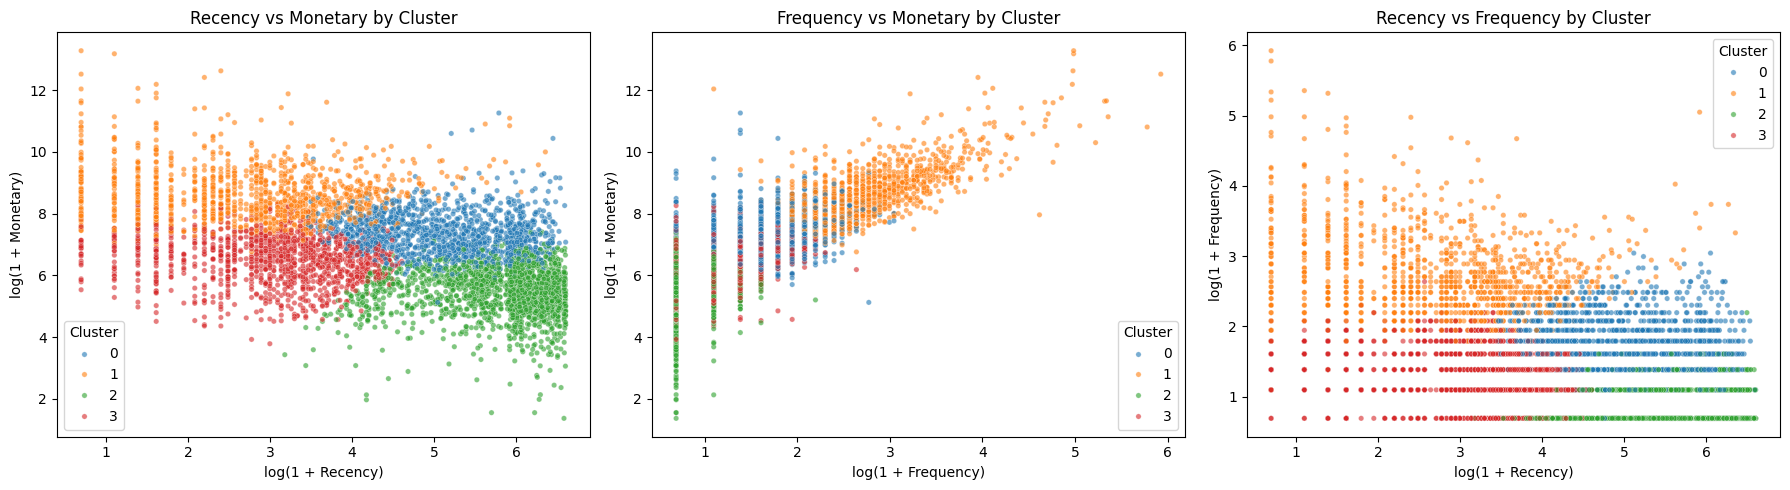

/tmp/ipykernel_581/852606795.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Cluster', data=rfm, palette='tab10')


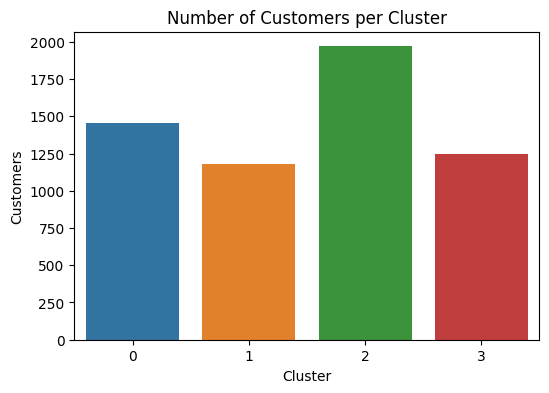

In [20]:
# 1) Fit K-Means with K = 4
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(X)

# 2) Cluster profile (original, not scaled, values)
profile = rfm.groupby('Cluster').agg(
    Customers=('Customer ID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Median_Monetary=('Monetary', 'median')
).round(1)
profile['Customer share %'] = (profile['Customers'] / len(rfm) * 100).round(1)
profile['Revenue share %'] = (rfm.groupby('Cluster')['Monetary'].sum() / rfm['Monetary'].sum() * 100).round(1)
print(profile)

# 3) Scatter plots (log scale so points are readable)
plot_df = rfm_log.copy()
plot_df['Cluster'] = rfm['Cluster']

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
pairs = [('Recency', 'Monetary'), ('Frequency', 'Monetary'), ('Recency', 'Frequency')]
for a, (xcol, ycol) in zip(ax, pairs):
    sns.scatterplot(data=plot_df, x=xcol, y=ycol, hue='Cluster',
                    palette='tab10', s=15, alpha=0.6, ax=a)
    a.set_title(f'{xcol} vs {ycol} by Cluster')
    a.set_xlabel(f'log(1 + {xcol})')
    a.set_ylabel(f'log(1 + {ycol})')
plt.tight_layout()
plt.show()

# 4) Number of customers per cluster
plt.figure(figsize=(6, 4))
sns.countplot(x='Cluster', data=rfm, palette='tab10')
plt.title('Number of Customers per Cluster')
plt.ylabel('Customers')
plt.show()

In [21]:
segment_names = {1: 'Champions', 3: 'Recent / Promising', 0: 'At Risk', 2: 'Lost / Inactive'}
rfm['Segment'] = rfm['Cluster'].map(segment_names)
print(rfm['Segment'].value_counts())

Segment
Lost / Inactive       1969
At Risk               1455
Recent / Promising    1246
Champions             1182
Name: count, dtype: int64


### Observations: Cluster Profiles (K = 4)

| Segment | Customers | Avg Recency (days) | Avg Frequency | Avg Monetary | Customer share | Revenue share |
|---|---|---|---|---|---|---|
| Champions (Cluster 1) | 1,182 | 27.6 | 19.2 | 10,590 | 20.2% | 73.3% |
| Recent / Promising (Cluster 3) | 1,246 | 28.2 | 3.0 | 841 | 21.3% | 6.1% |
| At Risk (Cluster 0) | 1,455 | 227.4 | 5.1 | 1,978 | 24.9% | 16.9% |
| Lost / Inactive (Cluster 2) | 1,969 | 392.6 | 1.4 | 317 | 33.6% | 3.7% |

- **Champions** are only about 20% of customers but generate about **73% of revenue**. They bought recently (about 28 days ago on average), buy often (about 19 invoices) and spend the most.
- **Recent / Promising** customers also bought recently but have placed only about 3 invoices and spend little so far. They are possible future Champions.
- **At Risk** customers used to buy fairly often and spend a decent amount, but have not purchased for about 7 to 8 months.
- **Lost / Inactive** is the largest group (33.6% of customers) but contributes only 3.7% of revenue. They bought about once and have not returned for over a year.
- **Scatter plots:** Frequency and Monetary are positively related, and Champions sit in the top-right of that plot. In the Recency plots, Lost / Inactive customers sit at high recency and low spending. The clusters overlap at their borders, which matches the moderate silhouette score (about 0.37): customer behaviour changes gradually, so some customers near a boundary could belong to a neighbouring segment. The horizontal stripes in the Recency vs Frequency plot appear because Frequency is a whole number.
- **Bar chart:** the Lost / Inactive cluster is the largest (1,969 customers) and Champions the smallest (1,182).

## Insights and Marketing Recommendations

These are suggestions based on the segments found, not proven results.

1. **Champions (20% of customers, 73% of revenue):** protect and reward them with early access to new products, loyalty or volume discounts, and a dedicated contact. Losing even a few of them would cost a lot of revenue.
2. **Recent / Promising:** encourage a second and third purchase with a welcome series, a "next order" discount, and product recommendations based on their first purchase. The goal is to move them towards the Champions group.
3. **At Risk:** run win-back campaigns such as "we miss you" emails, personalised offers on products they bought before, or a limited-time discount. They have shown real purchasing power before, so they are worth the effort.
4. **Lost / Inactive:** use low-cost, low-effort outreach only, such as one reactivation email or a seasonal offer. Because they contribute little revenue, avoid spending heavily on them.
5. **Overall:** since revenue is concentrated in one small group, the business should track the number of Champions over time and react quickly when their recency starts to rise.

## Conclusion and Limitations

Using RFM features, log transform, StandardScaler and K-Means with K = 4, the 5,852 customers were divided into four behavioural segments. A small group of Champions generates most of the revenue, while the largest group has become inactive.

**Limitations:**
- K = 4 is a reasonable choice (no sharp elbow, silhouette about 0.37), not a single "correct" answer. Other values of K could give different but still valid segments.
- Only Recency, Frequency and Monetary were used; product type, country and order size were not.
- The data covers a single UK-based online retailer over about two years, many of whose customers are wholesalers, so the results may not apply to other businesses.
- Monetary value is historical spending, not a prediction of future value.